In [13]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
sns.set_style("whitegrid"); SEED = 42

In [14]:
path = kagglehub.dataset_download("carrie1/ecommerce-data")
retail = pd.read_csv(f"{path}/data.csv", encoding="ISO-8859-1")
retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"])
print(retail.columns.tolist())
print(retail.shape)
retail.head()

Using Colab cache for faster access to the 'ecommerce-data' dataset.
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [15]:
retail = retail.dropna(subset=["CustomerID"])
retail["InvoiceNo"] = retail["InvoiceNo"].astype(str)
retail = retail[~retail["InvoiceNo"].str.startswith("C")]            # drop cancellations
retail = retail[(retail.Quantity > 0) & (retail.UnitPrice > 0)]
retail["Revenue"] = retail.Quantity * retail.UnitPrice

snapshot = retail.InvoiceDate.max() + pd.Timedelta(days=1)
rfm = retail.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")).reset_index()
print(rfm.describe().round(2))

       CustomerID  Recency  Frequency   Monetary
count     4338.00  4338.00    4338.00    4338.00
mean     15300.41    92.54       4.27    2054.27
std       1721.81   100.01       7.70    8989.23
min      12346.00     1.00       1.00       3.75
25%      13813.25    18.00       1.00     307.41
50%      15299.50    51.00       2.00     674.48
75%      16778.75   142.00       5.00    1661.74
max      18287.00   374.00     209.00  280206.02


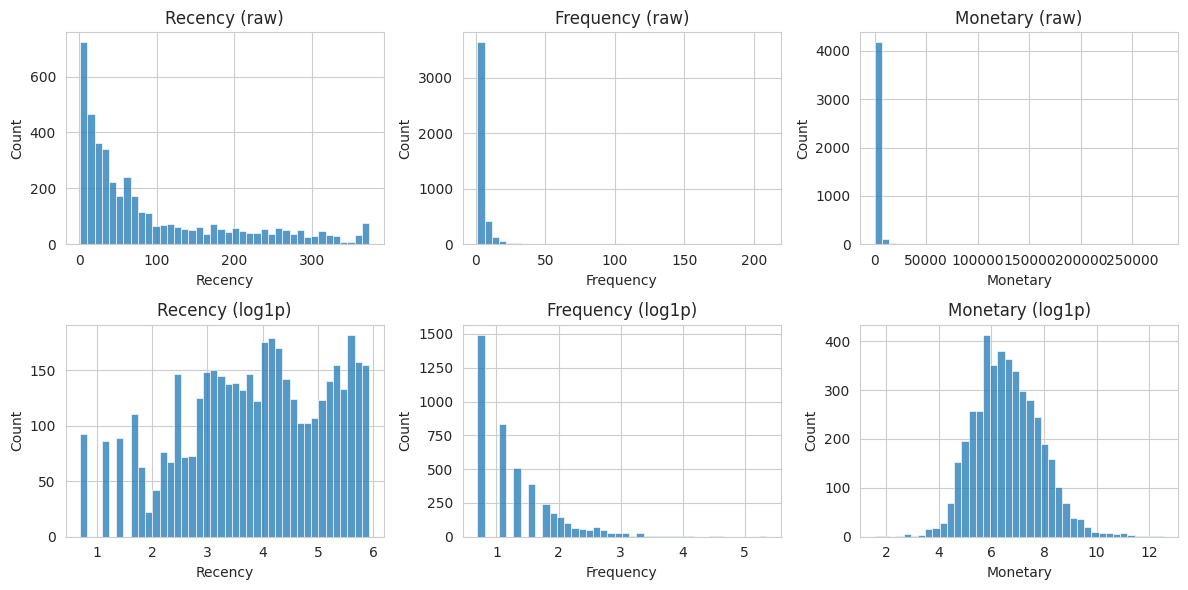

In [16]:
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for i, c in enumerate(["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[c], bins=40, ax=ax[0, i]).set_title(f"{c} (raw)")
    sns.histplot(np.log1p(rfm[c]), bins=40, ax=ax[1, i]).set_title(f"{c} (log1p)")
plt.tight_layout(); plt.show()

X_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
X = StandardScaler().fit_transform(X_log)

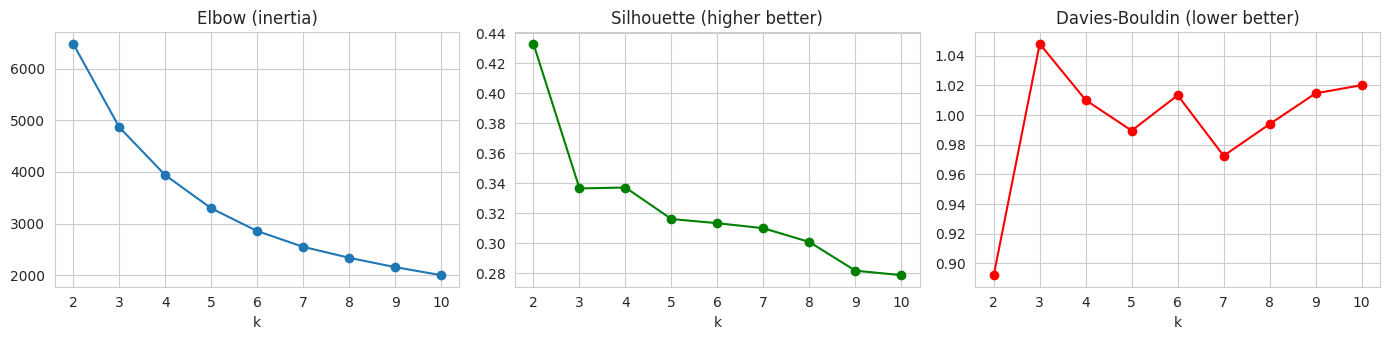

In [17]:
ks = range(2, 11); inertia, sil, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_)); dbi.append(davies_bouldin_score(X, km.labels_))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(ks, sil, "o-", c="g"); ax[1].set_title("Silhouette (higher better)")
ax[2].plot(ks, dbi, "o-", c="r"); ax[2].set_title("Davies-Bouldin (lower better)")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()

In [18]:
K = 4   # adjust based on the plots above
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X)
rfm["KMeans"] = km.labels_
print("Silhouette:", round(silhouette_score(X, km.labels_), 3))
print(rfm.groupby("KMeans")[["Recency", "Frequency", "Monetary"]].agg(["mean", "median"]).round(1))
print(rfm.KMeans.value_counts().sort_index())

Silhouette: 0.337
       Recency        Frequency        Monetary        
          mean median      mean median     mean  median
KMeans                                                 
0        182.9  177.0       1.3    1.0    351.0   300.4
1         69.5   54.0       4.1    4.0   1819.7  1355.0
2         18.4   17.0       2.1    2.0    544.4   468.3
3         11.9    8.0      13.8   10.0   8151.2  3738.4
KMeans
0    1617
1    1176
2     840
3     705
Name: count, dtype: int64


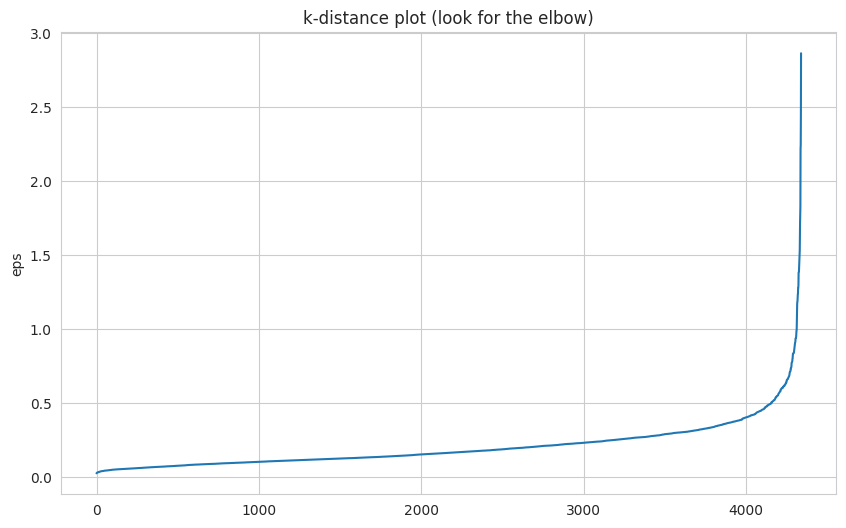

In [19]:
min_samples = 10
nbrs = NearestNeighbors(n_neighbors=min_samples).fit(X)
kdist = np.sort(nbrs.kneighbors(X)[0][:, -1])
plt.plot(kdist); plt.title("k-distance plot (look for the elbow)"); plt.ylabel("eps"); plt.show()

In [20]:
eps = 0.5   # set from the elbow above
db = DBSCAN(eps=eps, min_samples=min_samples).fit(X)
rfm["DBSCAN"] = db.labels_
n_cl = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
print("Clusters:", n_cl, "| Noise points:", (db.labels_ == -1).sum())
mask = db.labels_ != -1
if n_cl > 1:
    print("Silhouette (non-noise):", round(silhouette_score(X[mask], db.labels_[mask]), 3))
print(rfm.groupby("DBSCAN")[["Recency", "Frequency", "Monetary"]].mean().round(1))

Clusters: 2 | Noise points: 79
Silhouette (non-noise): 0.294
        Recency  Frequency  Monetary
DBSCAN                              
-1         57.6       28.4   36514.0
 0         59.2        5.3    1981.2
 1        157.1        1.0     351.0


Explained variance: [0.751 0.188 0.061] | cumulative: [0.751 0.939 1.   ]
     Recency  Frequency  Monetary
PC1    -0.51       0.62      0.60
PC2     0.85       0.26      0.46
PC3     0.13       0.74     -0.66


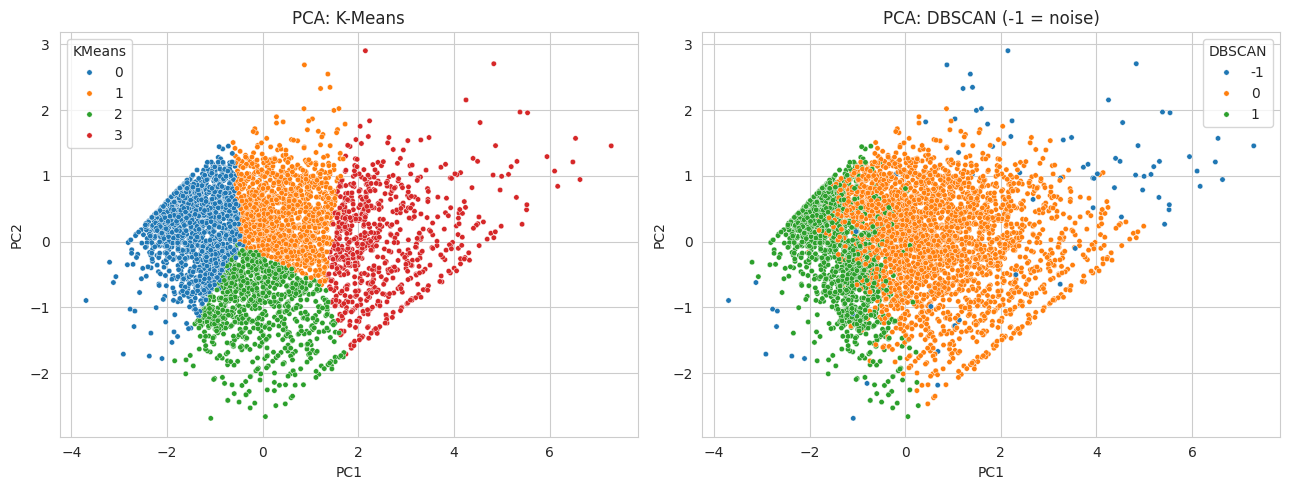

In [21]:
pca = PCA(n_components=3).fit(X)
print("Explained variance:", pca.explained_variance_ratio_.round(3), "| cumulative:", pca.explained_variance_ratio_.cumsum().round(3))
print(pd.DataFrame(pca.components_, columns=["Recency", "Frequency", "Monetary"], index=["PC1", "PC2", "PC3"]).round(2))

Z = PCA(n_components=2).fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=rfm.KMeans, palette="tab10", s=15, ax=ax[0]); ax[0].set_title("PCA: K-Means")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=rfm.DBSCAN, palette="tab10", s=15, ax=ax[1]); ax[1].set_title("PCA: DBSCAN (-1 = noise)")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

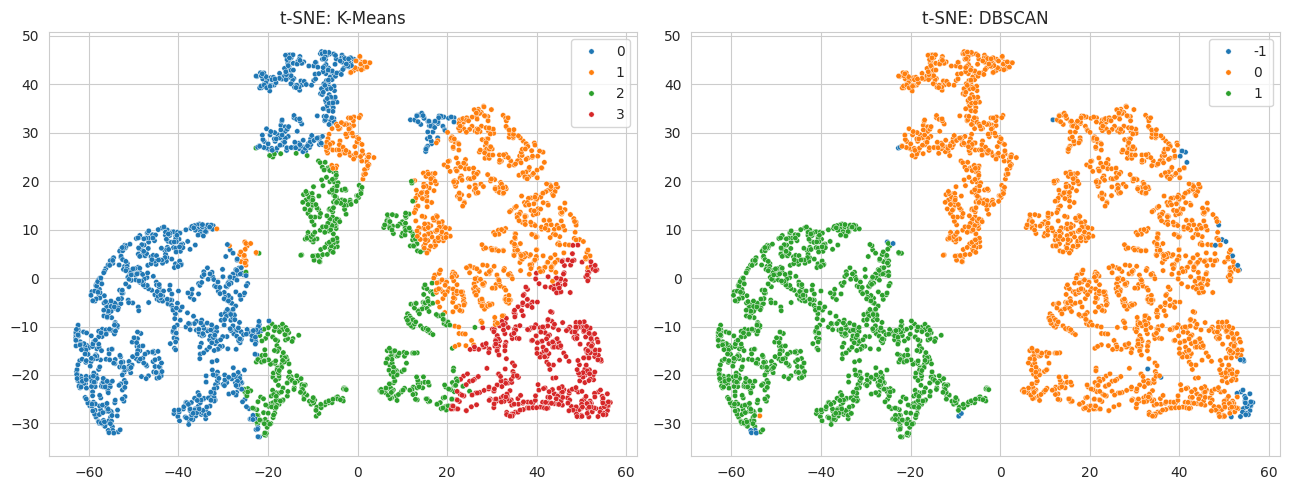

In [22]:
idx = np.random.default_rng(SEED).choice(len(X), min(3000, len(X)), replace=False)   # subsample for speed
tsne = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto", random_state=SEED)
T = tsne.fit_transform(X[idx])

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=rfm.KMeans.values[idx], palette="tab10", s=15, ax=ax[0]); ax[0].set_title("t-SNE: K-Means")
sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=rfm.DBSCAN.values[idx], palette="tab10", s=15, ax=ax[1]); ax[1].set_title("t-SNE: DBSCAN")
plt.tight_layout(); plt.show()

        Customers  Recency  Frequency  Monetary    Revenue  Revenue %
KMeans                                                               
0            1617    182.9        1.3     351.0   567548.4        6.4
1            1176     69.5        4.1    1819.7  2139968.9       24.0
2             840     18.4        2.1     544.4   457303.2        5.1
3             705     11.9       13.8    8151.2  5746587.3       64.5


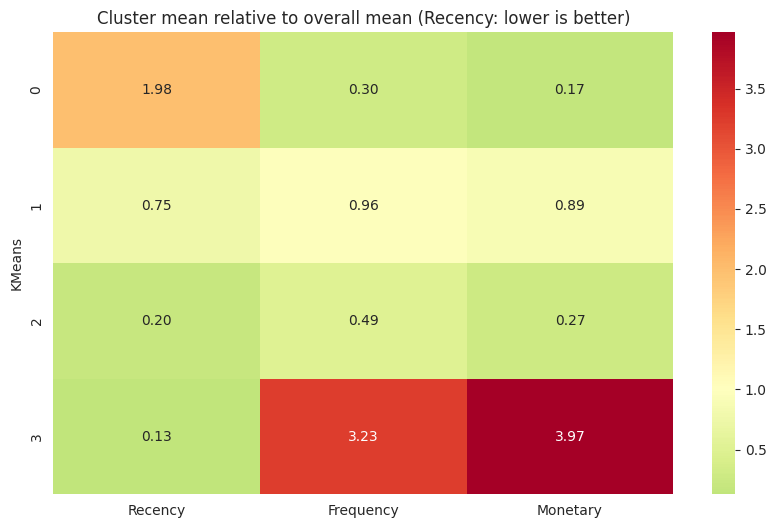

In [23]:
prof = rfm.groupby("KMeans").agg(
    Customers=("CustomerID", "count"),
    Recency=("Recency", "mean"), Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"), Revenue=("Monetary", "sum")).round(1)
prof["Revenue %"] = (prof.Revenue / prof.Revenue.sum() * 100).round(1)
print(prof)

rel = prof[["Recency", "Frequency", "Monetary"]] / rfm[["Recency", "Frequency", "Monetary"]].mean()
sns.heatmap(rel, annot=True, fmt=".2f", cmap="RdYlGn_r", center=1)
plt.title("Cluster mean relative to overall mean (Recency: lower is better)"); plt.show()

In [24]:
# Rule-based naming from relative RFM scores. Review manually against the heatmap.
def persona(r):
    if r.Monetary > 1.8 and r.Frequency > 1.8 and r.Recency < 0.6:
        return "Champions / VIPs"
    if r.Frequency > 1.0 and r.Recency < 1.0:
        return "Loyal Regulars"
    if r.Recency > 1.2 and r.Frequency < 0.7:
        return "Lapsed / At-Risk"
    return "New / Occasional"

names = rel.apply(persona, axis=1)
actions = {
    "Champions / VIPs":  "Early access, loyalty tiers, referral rewards. Avoid heavy discounting.",
    "Loyal Regulars":    "Cross-sell and bundles, subscription offers, points programs.",
    "Lapsed / At-Risk":  "Win-back emails with time-limited incentives, 'we miss you' campaigns, surveys.",
    "New / Occasional":  "Onboarding series, second-purchase coupon, product education."}
rfm["Persona"] = rfm.KMeans.map(names)
summary = prof.assign(Persona=names, Action=names.map(actions))
print(summary[["Customers", "Recency", "Frequency", "Monetary", "Revenue %", "Persona", "Action"]].to_string())

rfm.to_csv("customer_segments.csv", index=False)

        Customers  Recency  Frequency  Monetary  Revenue %           Persona                                                                           Action
KMeans                                                                                                                                                       
0            1617    182.9        1.3     351.0        6.4  Lapsed / At-Risk  Win-back emails with time-limited incentives, 'we miss you' campaigns, surveys.
1            1176     69.5        4.1    1819.7       24.0  New / Occasional                    Onboarding series, second-purchase coupon, product education.
2             840     18.4        2.1     544.4        5.1  New / Occasional                    Onboarding series, second-purchase coupon, product education.
3             705     11.9       13.8    8151.2       64.5  Champions / VIPs          Early access, loyalty tiers, referral rewards. Avoid heavy discounting.
